## 1. Importação das Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
%pip install statsmodels

## 2. Carregamento dos Dados e Visualização da Série Temporal

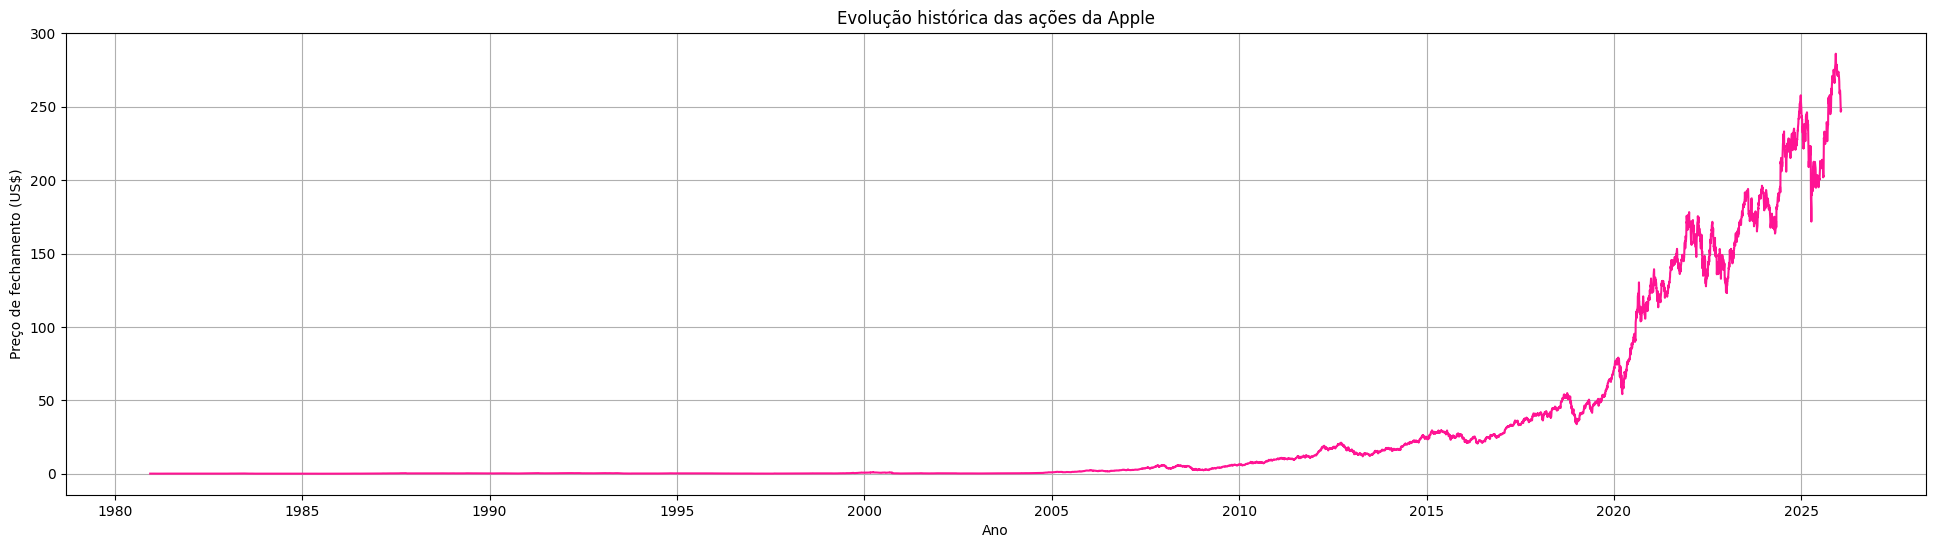

In [3]:
# Importando os dados
df = pd.read_csv('aapl_master_enriched.csv')

# Convertendo a coluna de datas
df['date'] = pd.to_datetime(df['date'])

# Organizando os registros cronologicamente
df = df.sort_values('date')

# Definindo a data como índice
df = df.set_index('date')

# Visualizando a série temporal
plt.figure(figsize=(24, 6))
plt.plot(df.index, df['close'], color='deeppink')

plt.title('Evolução histórica das ações da Apple')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.grid(True)
plt.show()


## 3. Decomposição da Série Temporal: Tendência, Sazonalidade e Resíduos

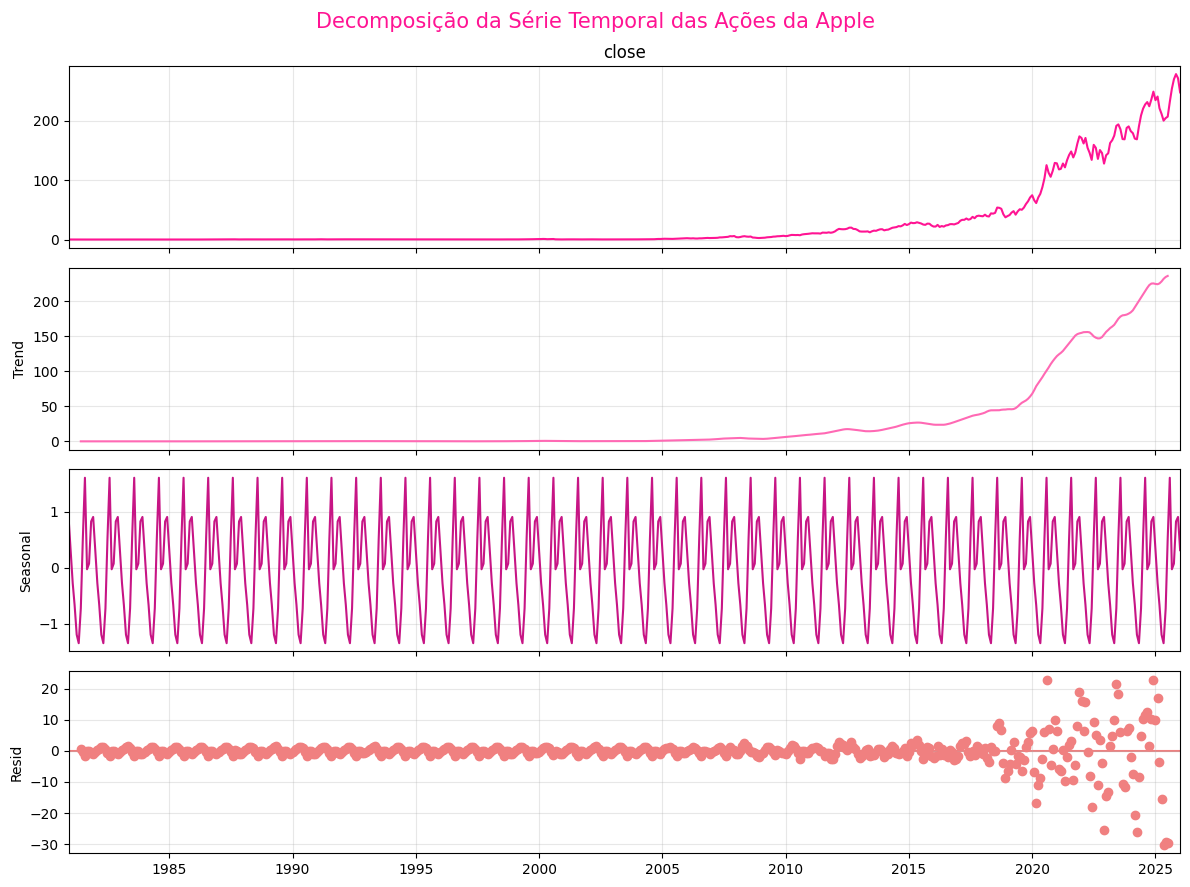

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Transformando os dados diários em mensais
serie_mensal = df['close'].resample('MS').last()

# Removendo possíveis valores ausentes
serie_mensal = serie_mensal.dropna()

# Realizando a decomposição da série temporal
decomposicao = seasonal_decompose(
    serie_mensal,
    model='additive',
    period=12
)

# Criando os gráficos
fig = decomposicao.plot()
fig.set_size_inches(12, 9)

# Alterando as linhas para tons de rosa
cores = ['deeppink', 'hotpink', 'mediumvioletred', 'lightcoral']

for ax, cor in zip(fig.axes, cores):
    for linha in ax.get_lines():
        linha.set_color(cor)
        linha.set_linewidth(1.5)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'Decomposição da Série Temporal das Ações da Apple',
    fontsize=15,
    color='deeppink'
)

plt.tight_layout()
plt.show()


## 4. Previsão da Série Temporal com Holt-Winters

Último mês do treino: 12/2024
Teste: 01/2025 a 12/2025
Meses no teste: 12


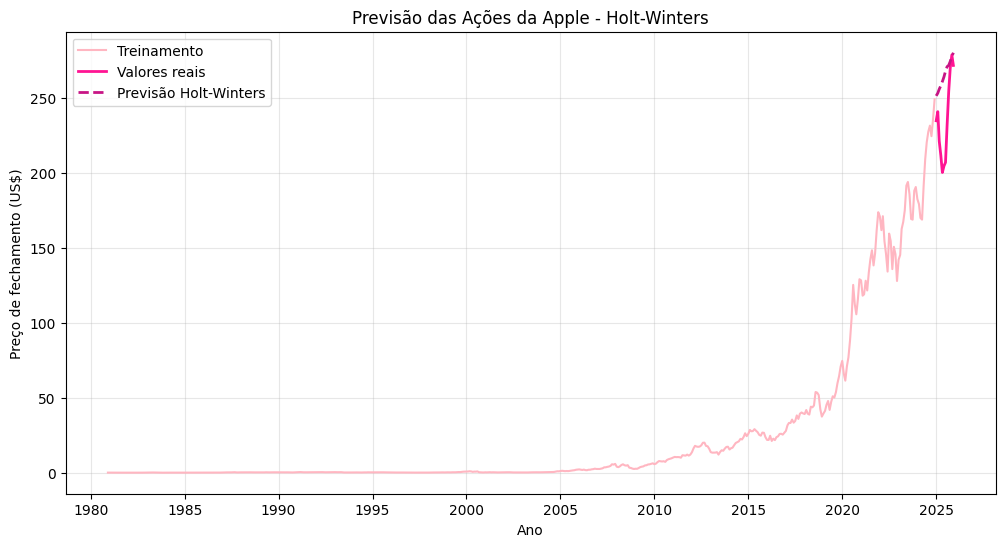

Resultados do Holt-Winters:
MAE: 30.1617
RMSE: 37.2605
MAPE: 13.96%


In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Separando os dados de treinamento e teste

# Usa os fechamentos mensais até o último mês completo do CSV
serie_previsao = serie_mensal.loc[:'2025-12']

# Os 12 meses de 2025 ficam reservados para teste
treino = serie_previsao.iloc[:-12]
teste = serie_previsao.iloc[-12:]

print(f'Último mês do treino: {treino.index[-1]:%m/%Y}')
print(f'Teste: {teste.index[0]:%m/%Y} a {teste.index[-1]:%m/%Y}')
print(f'Meses no teste: {len(teste)}')

# 2. Criando e treinando o modelo Holt-Winters
modelo_hw = ExponentialSmoothing(
    treino,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
)

ajuste_hw = modelo_hw.fit(optimized=True)

# 3. Prevendo os 12 meses do teste (janeiro a dezembro de 2025)

#previsao_hw = ajuste_hw.forecast(12)
previsao_hw = ajuste_hw.forecast(steps=len(teste))

# 4. Visualizando os resultados
plt.figure(figsize=(12, 6))

plt.plot(treino.index, treino,
         label='Treinamento', color='lightpink')

plt.plot(teste.index, teste,
         label='Valores reais', color='deeppink',
         linewidth=2)

plt.plot(previsao_hw.index, previsao_hw,
         label='Previsão Holt-Winters',
         color='mediumvioletred',
         linestyle='--', linewidth=2)

plt.title('Previsão das Ações da Apple - Holt-Winters')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5. Calculando os erros
mae_hw = mean_absolute_error(teste, previsao_hw)
rmse_hw = np.sqrt(mean_squared_error(teste, previsao_hw))
mape_hw = np.mean(np.abs((teste - previsao_hw) / teste)) * 100

print("Resultados do Holt-Winters:")
print(f"MAE: {mae_hw:.4f}")
print(f"RMSE: {rmse_hw:.4f}")
print(f"MAPE: {mape_hw:.2f}%")


## 5. Previsão da série temporal com o modelo SARIMA

Ajustamos o SARIMA com dados até dezembro de 2024 e prevemos os 12 meses de 2025.

In [6]:
# Ajustando o ARIMA apenas com os dados de treinamento
modelo_arima = ARIMA(
    np.log(treino),
    order=(1, 1, 0),
    seasonal_order=(1, 0, 0, 12)
)
ajuste_arima = modelo_arima.fit()
# Prevendo a mesma quantidade de meses do conjunto de teste
# np.exp converte a previsão do log de volta para dólares
previsao_arima = np.exp(ajuste_arima.forecast(steps=len(teste)))

### 5.1. Previsões do SARIMA e valores reais de 2025

Comparamos as previsões do SARIMA com os preços reais de fechamento de cada mês do teste.

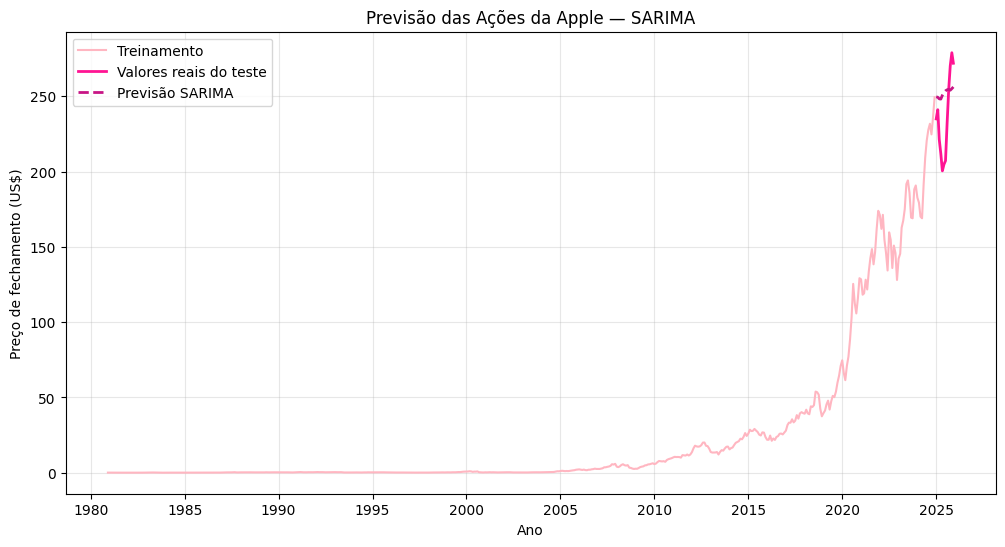

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(treino.index, treino, label='Treinamento', color='lightpink')
plt.plot(teste, label='Valores reais do teste', color='deeppink', linewidth=2)
plt.plot(previsao_arima, label='Previsão SARIMA',
         color='mediumvioletred', linestyle='--', linewidth=2)

plt.title('Previsão das Ações da Apple — SARIMA')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Previsão da série temporal com o modelo Prophet

Treinamos o Prophet com os fechamentos mensais até dezembro de 2024
e comparamos suas previsões com os 12 fechamentos reais de 2025.

In [12]:
%pip install prophet

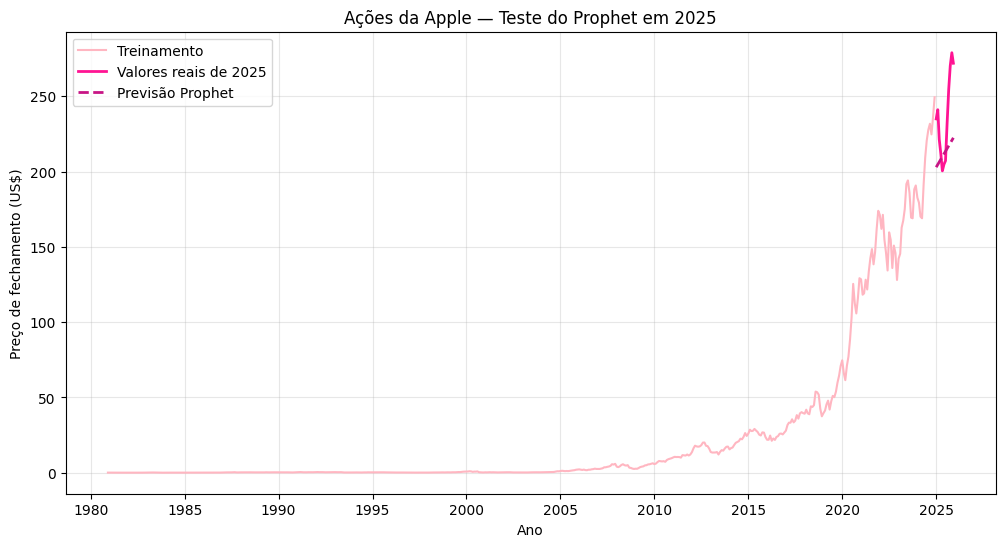

In [13]:
from prophet import Prophet

def ajustar_prophet(serie):
    # ds é a data e y é o preço de fechamento
    dados = pd.DataFrame({'ds': serie.index, 'y': serie.to_numpy()})

    modelo = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=False,
        daily_seasonality=False
    )
    return modelo.fit(dados)

# O modelo recebe apenas os preços do treino
modelo_prophet = ajustar_prophet(treino)

# O modelo recebe as datas de 2025 para prever, sem os preços reais
datas_teste = pd.DataFrame({'ds': teste.index})
previsao_prophet = modelo_prophet.predict(datas_teste).set_index('ds')['yhat']

plt.figure(figsize=(12, 6))
plt.plot(treino.index, treino, color='lightpink', label='Treinamento')
plt.plot(teste.index, teste, color='deeppink', linewidth=2,
         label='Valores reais de 2025')
plt.plot(previsao_prophet.index, previsao_prophet, '--',
         color='mediumvioletred', linewidth=2, label='Previsão Prophet')
plt.title('Ações da Apple — Teste do Prophet em 2025')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Comparação visual entre Holt-Winters, SARIMA e Prophet
Mostramos as previsões dos dois modelos lado a lado, com a mesma escala e o mesmo período de teste.

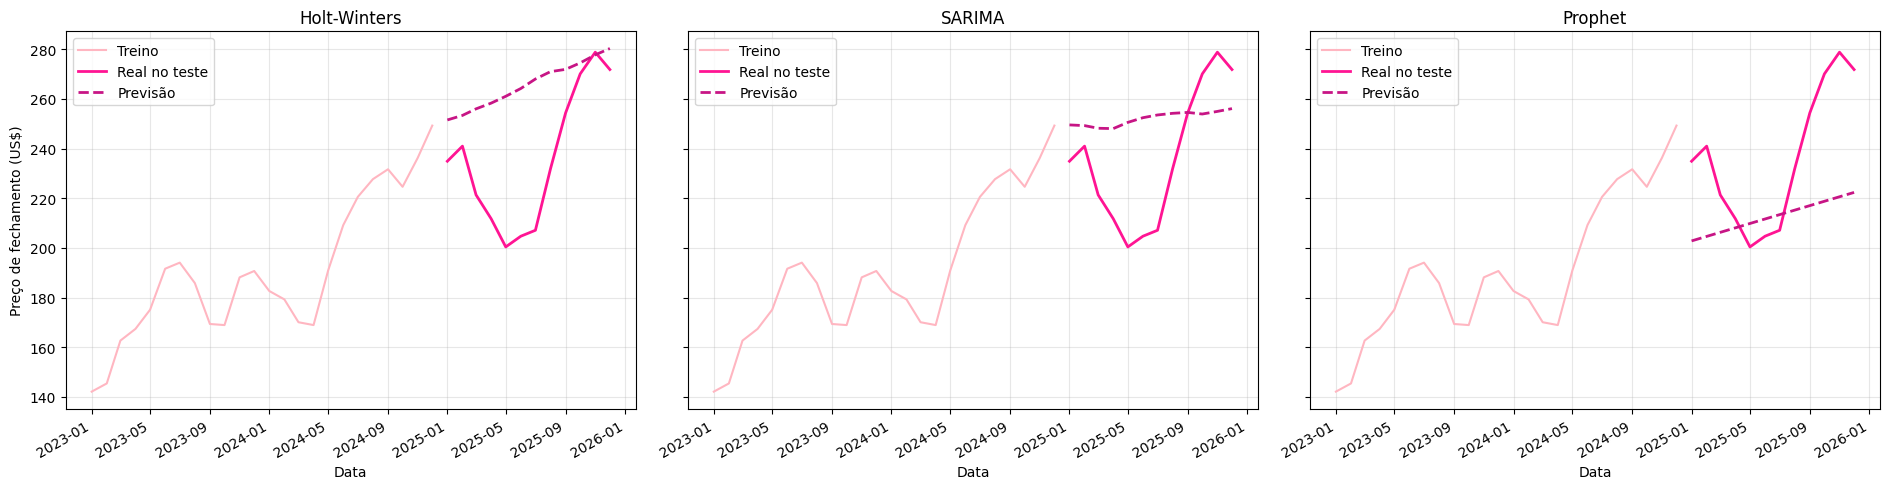

In [17]:
fig, eixos = plt.subplots(
    1, 3, figsize=(19, 5), sharex=True, sharey=True
)

historico = treino.tail(24)

for ax, nome, previsao in zip(
    eixos,
    ['Holt-Winters', 'SARIMA', 'Prophet'],
    [previsao_hw, previsao_arima, previsao_prophet]
):
    ax.plot(historico, color='lightpink', label='Treino')
    ax.plot(teste, color='deeppink', linewidth=2, label='Real no teste')
    ax.plot(previsao, color='mediumvioletred', linestyle='--',
            linewidth=2, label='Previsão')

    ax.set_title(nome)
    ax.set_xlabel('Data')
    ax.legend()
    ax.grid(alpha=0.3)

eixos[0].set_ylabel('Preço de fechamento (US$)')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 6.1. Comparação do erro médio dos modelos (MAE)

Calculamos quanto cada modelo errou, em média, em dólares, nos 12 meses de 2025. Quanto menor o MAE, mais próximas dos valores reais ficaram as previsões.

In [15]:
erro_prophet = teste - previsao_prophet

mae_prophet = erro_prophet.abs().mean()
rmse_prophet = np.sqrt(erro_prophet.pow(2).mean())
mape_prophet = (erro_prophet.abs() / teste).mean() * 100

comparacao = pd.DataFrame({
    'MAE (US$)': [mae_hw, mae_sarima, mae_prophet],
    'RMSE (US$)': [rmse_hw, rmse_sarima, rmse_prophet],
    'MAPE (%)': [mape_hw, mape_sarima, mape_prophet]
}, index=['Holt-Winters', 'SARIMA', 'Prophet'])

display(comparacao.sort_values('MAE (US$)').round(2))

,MAE (US$),RMSE (US$),MAPE (%)
SARIMA,25.72,30.06,11.64
Prophet,26.91,32.80,10.70
Holt-Winters,30.16,37.26,13.96


## Projeção para 2026 com SARIMA

Comparamos Holt-Winters e SARIMA nos mesmos 12 meses de 2025. O SARIMA apresentou o menor erro absoluto médio nesse teste. Por isso, ajustamos novamente o SARIMA com os dados até dezembro de 2025 e projetamos os fechamentos mensais de janeiro a dezembro de 2026.

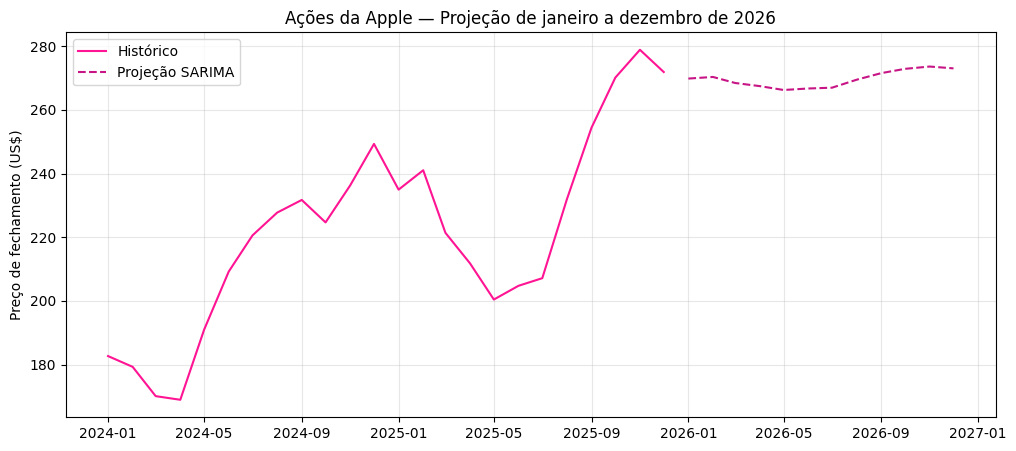

In [10]:
ajuste_final_sarima = ARIMA(
    np.log(serie_previsao),
    order=(1, 1, 0),
    seasonal_order=(1, 0, 0, 12)
).fit()

previsao_2026 = np.exp(ajuste_final_sarima.forecast(steps=12))

plt.figure(figsize=(12, 5))
plt.plot(serie_previsao.tail(24), color='deeppink', label='Histórico')
plt.plot(previsao_2026, '--', color='mediumvioletred', label='Projeção SARIMA')
plt.title('Ações da Apple — Projeção de janeiro a dezembro de 2026')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Projeção para 2026 com Holt-Winters

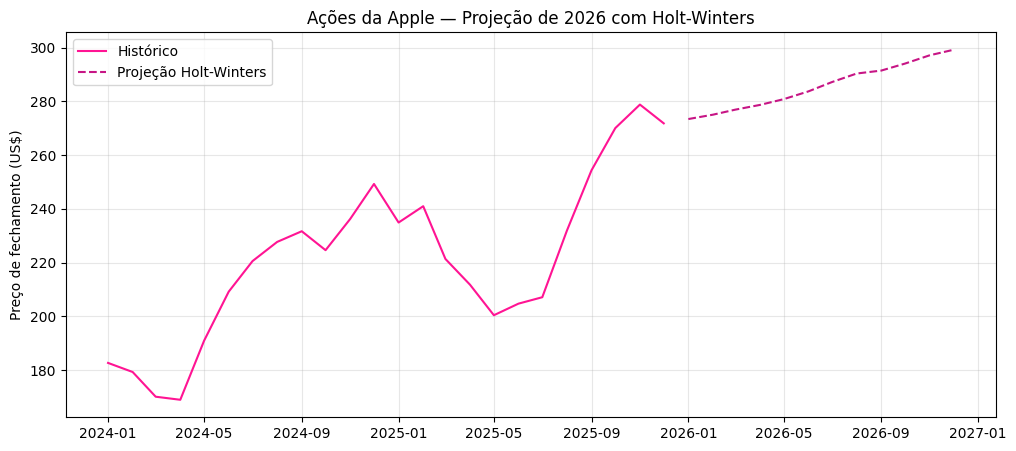

In [11]:
ajuste_final_hw = ExponentialSmoothing(
    serie_previsao,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
).fit(optimized=True)

previsao_2026_hw = ajuste_final_hw.forecast(steps=12)

plt.figure(figsize=(12, 5))
plt.plot(serie_previsao.tail(24), color='deeppink', label='Histórico')
plt.plot(previsao_2026_hw, '--', color='mediumvioletred',
         label='Projeção Holt-Winters')
plt.title('Ações da Apple — Projeção de 2026 com Holt-Winters')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Projeção para 2026 com Prophet

,Projeção Prophet (US$)
ds,
2026-01-01,238.55
2026-02-01,240.60
2026-03-01,242.45
2026-04-01,244.50
2026-05-01,246.49
2026-06-01,248.54
2026-07-01,250.52
2026-08-01,252.57
2026-09-01,254.62


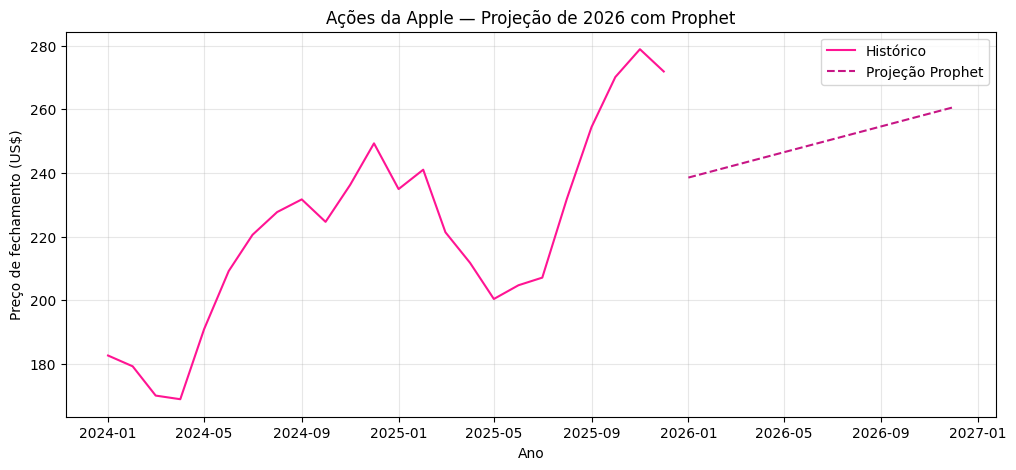

In [16]:
modelo_final_prophet = ajustar_prophet(serie_previsao)

datas_2026 = pd.DataFrame({
    'ds': pd.date_range('2026-01-01', periods=12, freq='MS')
})

previsao_2026_prophet = (
    modelo_final_prophet.predict(datas_2026).set_index('ds')['yhat']
)

display(previsao_2026_prophet.round(2).rename('Projeção Prophet (US$)'))

historico = serie_previsao.tail(24)

plt.figure(figsize=(12, 5))
plt.plot(historico.index, historico, color='deeppink', label='Histórico')
plt.plot(previsao_2026_prophet.index, previsao_2026_prophet, '--',
         color='mediumvioletred', label='Projeção Prophet')
plt.title('Ações da Apple — Projeção de 2026 com Prophet')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Análise da série temporal

**Tendência:** A série histórica apresenta tendência de crescimento no longo prazo, embora ocorram quedas e oscilações em diferentes períodos.

**Sazonalidade:** Foi realizada uma decomposição aditiva da série mensal, considerando um período de 12 meses. A presença de padrões sazonais deve ser avaliada pelo gráfico da componente sazonal; a decomposição, por si só, não comprova uma sazonalidade forte.

**Ciclos:** A série apresenta oscilações de médio e longo prazo que podem estar relacionadas a fatores econômicos, lançamentos de produtos e condições do mercado financeiro. Entretanto, não foi identificado formalmente um ciclo de duração fixa.

## Conclusões e impacto prático

A análise das ações da Apple demonstra como técnicas de séries temporais podem auxiliar na compreensão de tendências históricas e na elaboração de projeções financeiras. Na comparação realizada, o SARIMA apresentou melhor desempenho que o Holt-Winters.

Para investidores e empresas do setor financeiro, esse tipo de análise pode contribuir para o planejamento de cenários, avaliação de riscos e apoio à tomada de decisões. Entretanto, o mercado de ações é influenciado por acontecimentos econômicos, tecnológicos e políticos que não são totalmente capturados pelos modelos utilizados. Assim, as previsões devem ser interpretadas como estimativas, e não como garantias de valorização.